# Práctica 4 · Entrenamiento del detector de matrículas y comparativa OCR

Cuaderno ejecutado en **Google Colab**. Contiene:

1. Descarga del conjunto de datos de matrículas **UC3M-LP**
2. Conversión al formato YOLO
3. Entrenamiento de **YOLO11n** para detectar matrículas
4. Entrenamiento de **RT-DETR-L** (extra) con los mismos datos
5. **P4b:** comparativa de OCR entre **EasyOCR** (OCR clásico) y **SmolVLM** (VLM)

Se trabajó en varias sesiones de Colab (CPU para la descarga, GPU NVIDIA L4 para entrenar y para el OCR); por eso al inicio de cada sesión se vuelve a montar Google Drive. Los resultados se guardan en `MyDrive/VC_P4` para no perderlos al cerrar la sesión.

## 1. Descarga del conjunto de datos UC3M-LP (sesión con CPU)

[UC3M-LP](https://github.com/ramajoballester/uc3m-lp) (Universidad Carlos III de Madrid, licencia CC BY 4.0) es el mayor conjunto abierto de matrículas españolas: 1.975 imágenes y 2.547 matrículas. Se descarga desde [Zenodo](https://zenodo.org/records/17152029) (4,5 GB) directamente a Google Drive, así solo hay que descargarlo una vez.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


La descarga normal desde Zenodo iba a unos 0,6 MB/s (más de 2 horas). Con `aria2c` y 8 conexiones en paralelo bajó a unos 10 minutos.

In [ ]:
!apt-get -qq install -y aria2
!mkdir -p /content/drive/MyDrive/VC_P4
!aria2c -x 8 -s 8 -c -d /content/drive/MyDrive/VC_P4 -o UC3M-LP.zip "https://zenodo.org/records/17152029/files/UC3M-LP.zip?download=1"

Selecting previously unselected package libcares2:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../libcares2_1.27.0-1.0ubuntu1_amd64.deb ...
Unpacking libcares2:amd64 (1.27.0-1.0ubuntu1) ...
Selecting previously unselected package libaria2-0:amd64.
Preparing to unpack .../libaria2-0_1.37.0+debian-1build3_amd64.deb ...
Unpacking libaria2-0:amd64 (1.37.0+debian-1build3) ...
Selecting previously unselected package aria2.
Preparing to unpack .../aria2_1.37.0+debian-1build3_amd64.deb ...
Unpacking aria2 (1.37.0+debian-1build3) ...
Setting up libcares2:amd64 (1.27.0-1.0ubuntu1) ...
Setting up libaria2-0:amd64 (1.37.0+debian-1build3) ...
Setting up aria2 (1.37.0+debian-1build3) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.real: /usr/local/lib/libtbb.so.12 is not a symbolic link

/sbin/ldconfig.real: /usr/local/lib/libhwloc.so.15 is not a symbolic link

/sbin/

## 2. Preparación de la sesión con GPU (NVIDIA L4)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi
!pip install -q ultralytics

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Fri Nov  6 23:11:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   39C    P8             12W /   72W |       0MiB /  23034MiB |      0%      Default |
|          

## 3. Conversión al formato YOLO

Se descomprime el conjunto de datos en el disco local de Colab (más rápido que leer desde Drive) y se muestra la estructura de carpetas.

In [ ]:
!unzip -q /content/drive/MyDrive/VC_P4/UC3M-LP.zip -d /content/UC3M-LP
!find /content/UC3M-LP -maxdepth 3 -not -name "*.jpg" -not -name "*.json" | head -30

/content/UC3M-LP
/content/UC3M-LP/UC3M-LP
/content/UC3M-LP/UC3M-LP/train.txt
/content/UC3M-LP/UC3M-LP/test
/content/UC3M-LP/UC3M-LP/train
/content/UC3M-LP/UC3M-LP/test.txt


Para la conversión se usa sin cambios el script `labels2yolo.py` de los autores del conjunto de datos. Convierte el polígono de cada matrícula en una caja en formato YOLO (clase 0) y reescala las imágenes a 1280 px en el lado mayor. El segundo parámetro (160) es el tamaño de los recortes para OCR que también genera el script y que aquí no se usan.

El script usa la partición oficial: 1.580 imágenes de *train* y las 395 de *test* como validación (`val`).

In [ ]:
!git clone -q https://github.com/ramajoballester/uc3m-lp.git /content/uc3m-lp
!pip install -q shapely
!python /content/uc3m-lp/scripts/labels2yolo.py /content/UC3M-LP/UC3M-LP 1280 160

Processing train split
100% 1580/1580 [05:41<00:00,  4.63it/s]
Processing test split
100% 395/395 [01:22<00:00,  4.80it/s]


### Archivo de configuración del conjunto de datos

Basado en la plantilla del README de la práctica: una sola clase (`matricula`).

In [ ]:
yaml_texto = """path: /content/UC3M-LP/UC3M-LP-yolo/LP
train: images/train
val: images/val

nc: 1
names: ['matricula']
"""
with open("/content/matriculas.yaml", "w") as f:
    f.write(yaml_texto)

print(open("/content/matriculas.yaml").read())

path: /content/UC3M-LP/UC3M-LP-yolo/LP
train: images/train
val: images/val

nc: 1
names: ['matricula']



## 4. Entrenamiento de YOLO11n

Plantilla del README de la práctica: `yolo detect train model=yolo11n.pt data=... imgsz=416 batch=4 device=CPU epochs=40`

Cambios: `device=0` (GPU), `imgsz=640` (las matrículas son pequeñas), `batch=16`, `epochs=50` y guardado de los resultados en Google Drive.

In [ ]:
!yolo detect train model=yolo11n.pt data=/content/matriculas.yaml imgsz=640 batch=16 device=0 epochs=50 project=/content/drive/MyDrive/VC_P4/runs name=yolo11n_matriculas

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/matriculas.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, free

### Curvas de entrenamiento de YOLO11n

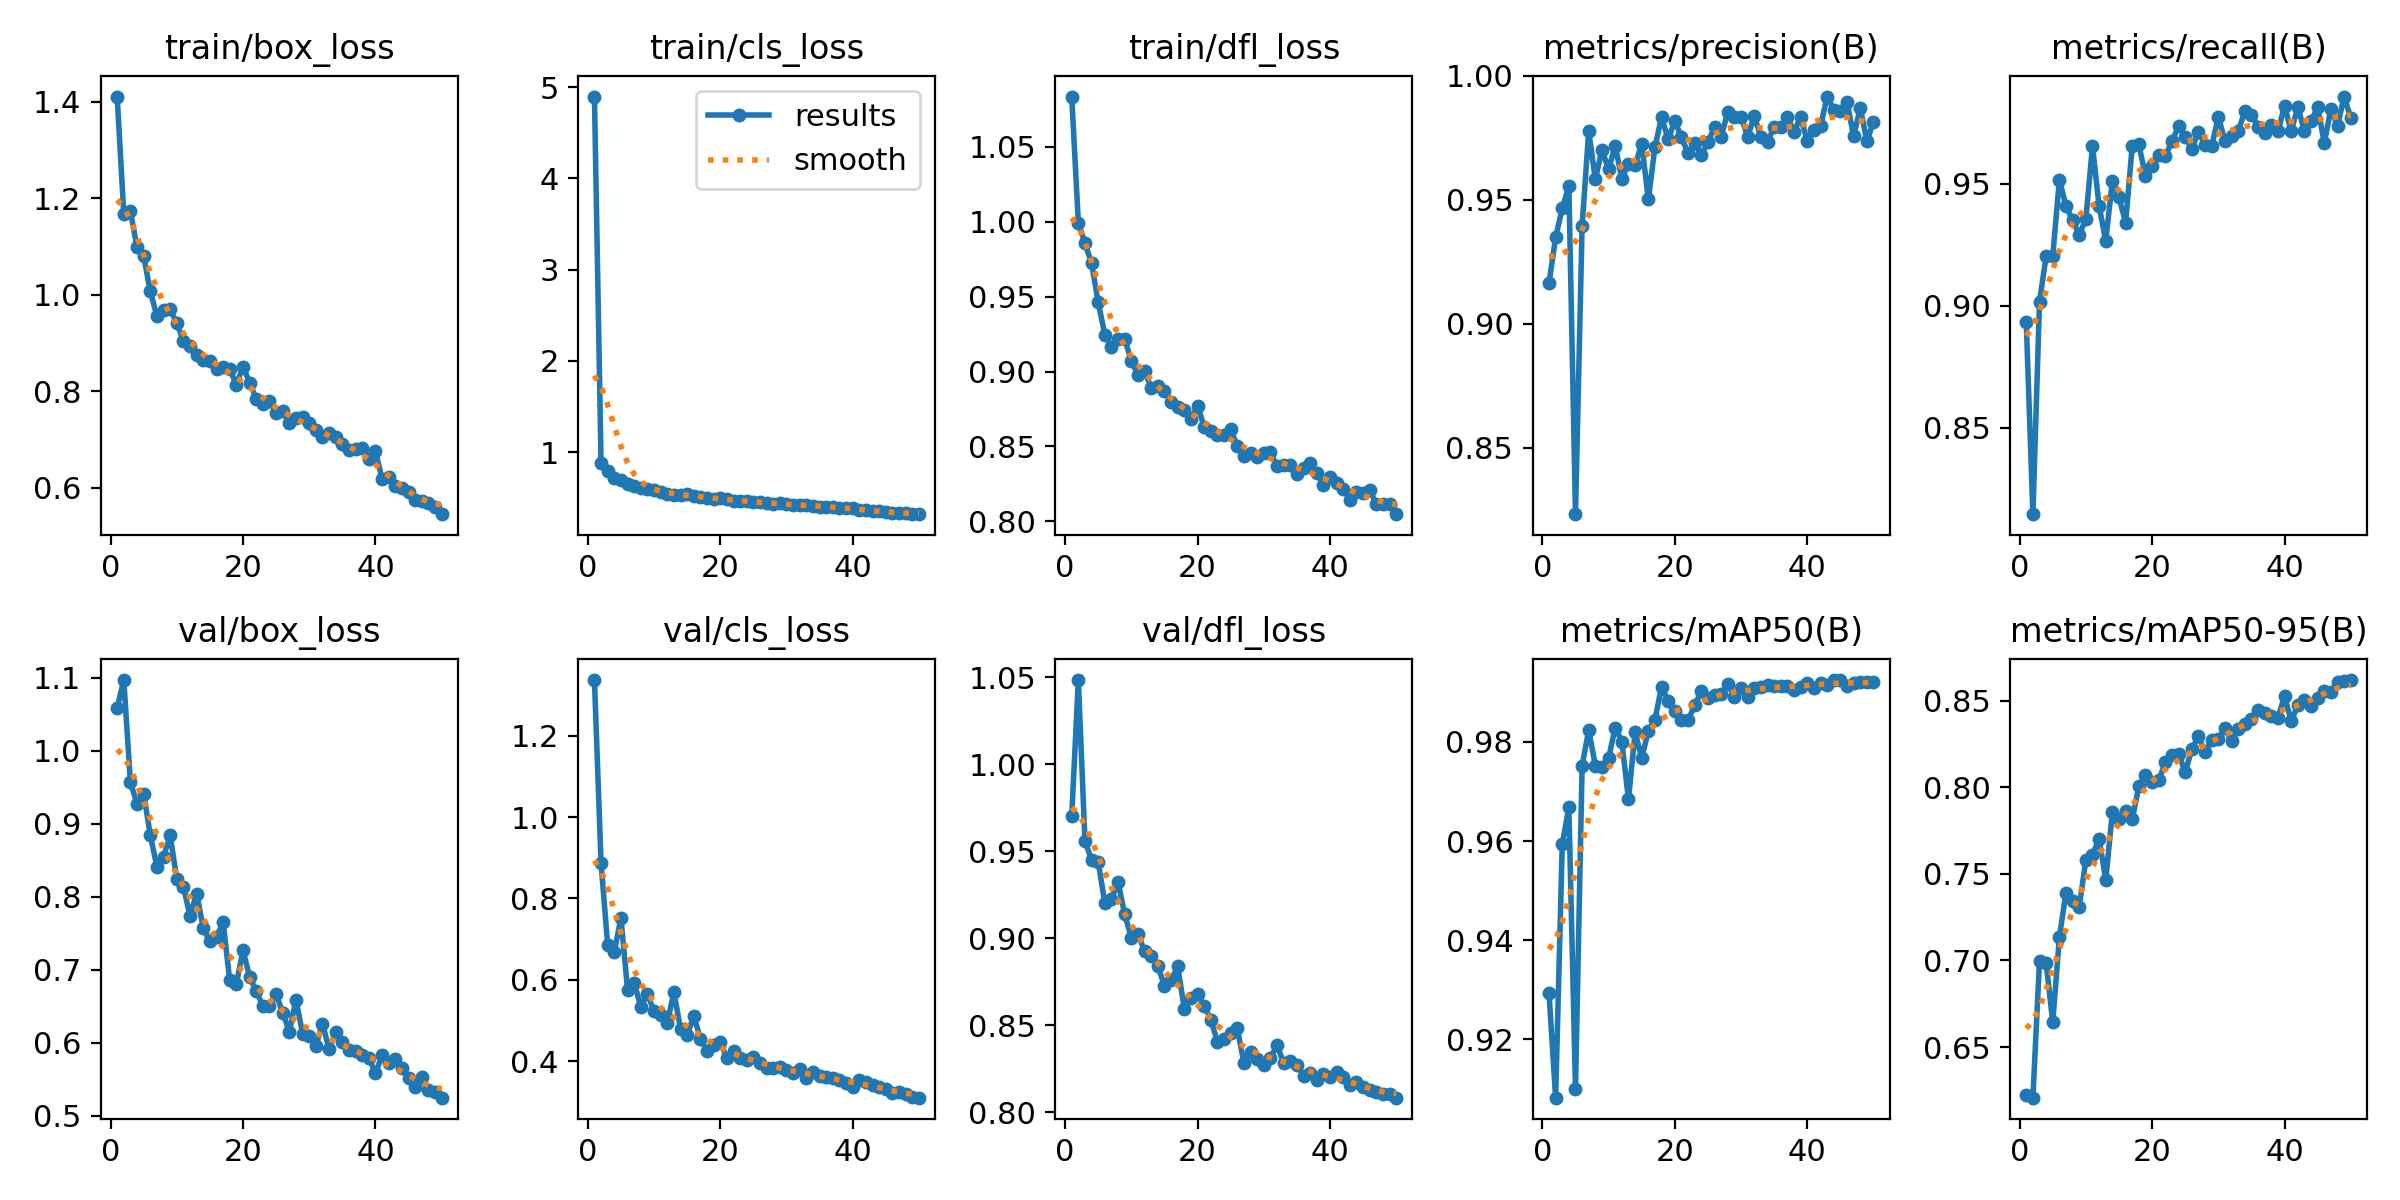

In [ ]:
from IPython.display import Image, display
display(Image("/content/drive/MyDrive/VC_P4/runs/yolo11n_matriculas/results.png"))

## 5. Entrenamiento de RT-DETR-L (extra)

Se usa la implementación de RT-DETR incluida en Ultralytics, con el mismo conjunto de datos, `imgsz` y número de épocas que YOLO para que la comparativa sea justa. Solo cambia el `batch` (8), porque RT-DETR necesita más memoria de GPU.

In [ ]:
!yolo detect train model=rtdetr-l.pt data=/content/matriculas.yaml imgsz=640 batch=8 device=0 epochs=50 project=/content/drive/MyDrive/VC_P4/runs name=rtdetr_matriculas

Ultralytics 8.4.204 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA L4, 22563MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/matriculas.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=rtdetr-l.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rtdetr_matriculas, nbs=64, nms=None, opset=None, optimize=False

### Curvas de entrenamiento de RT-DETR-L

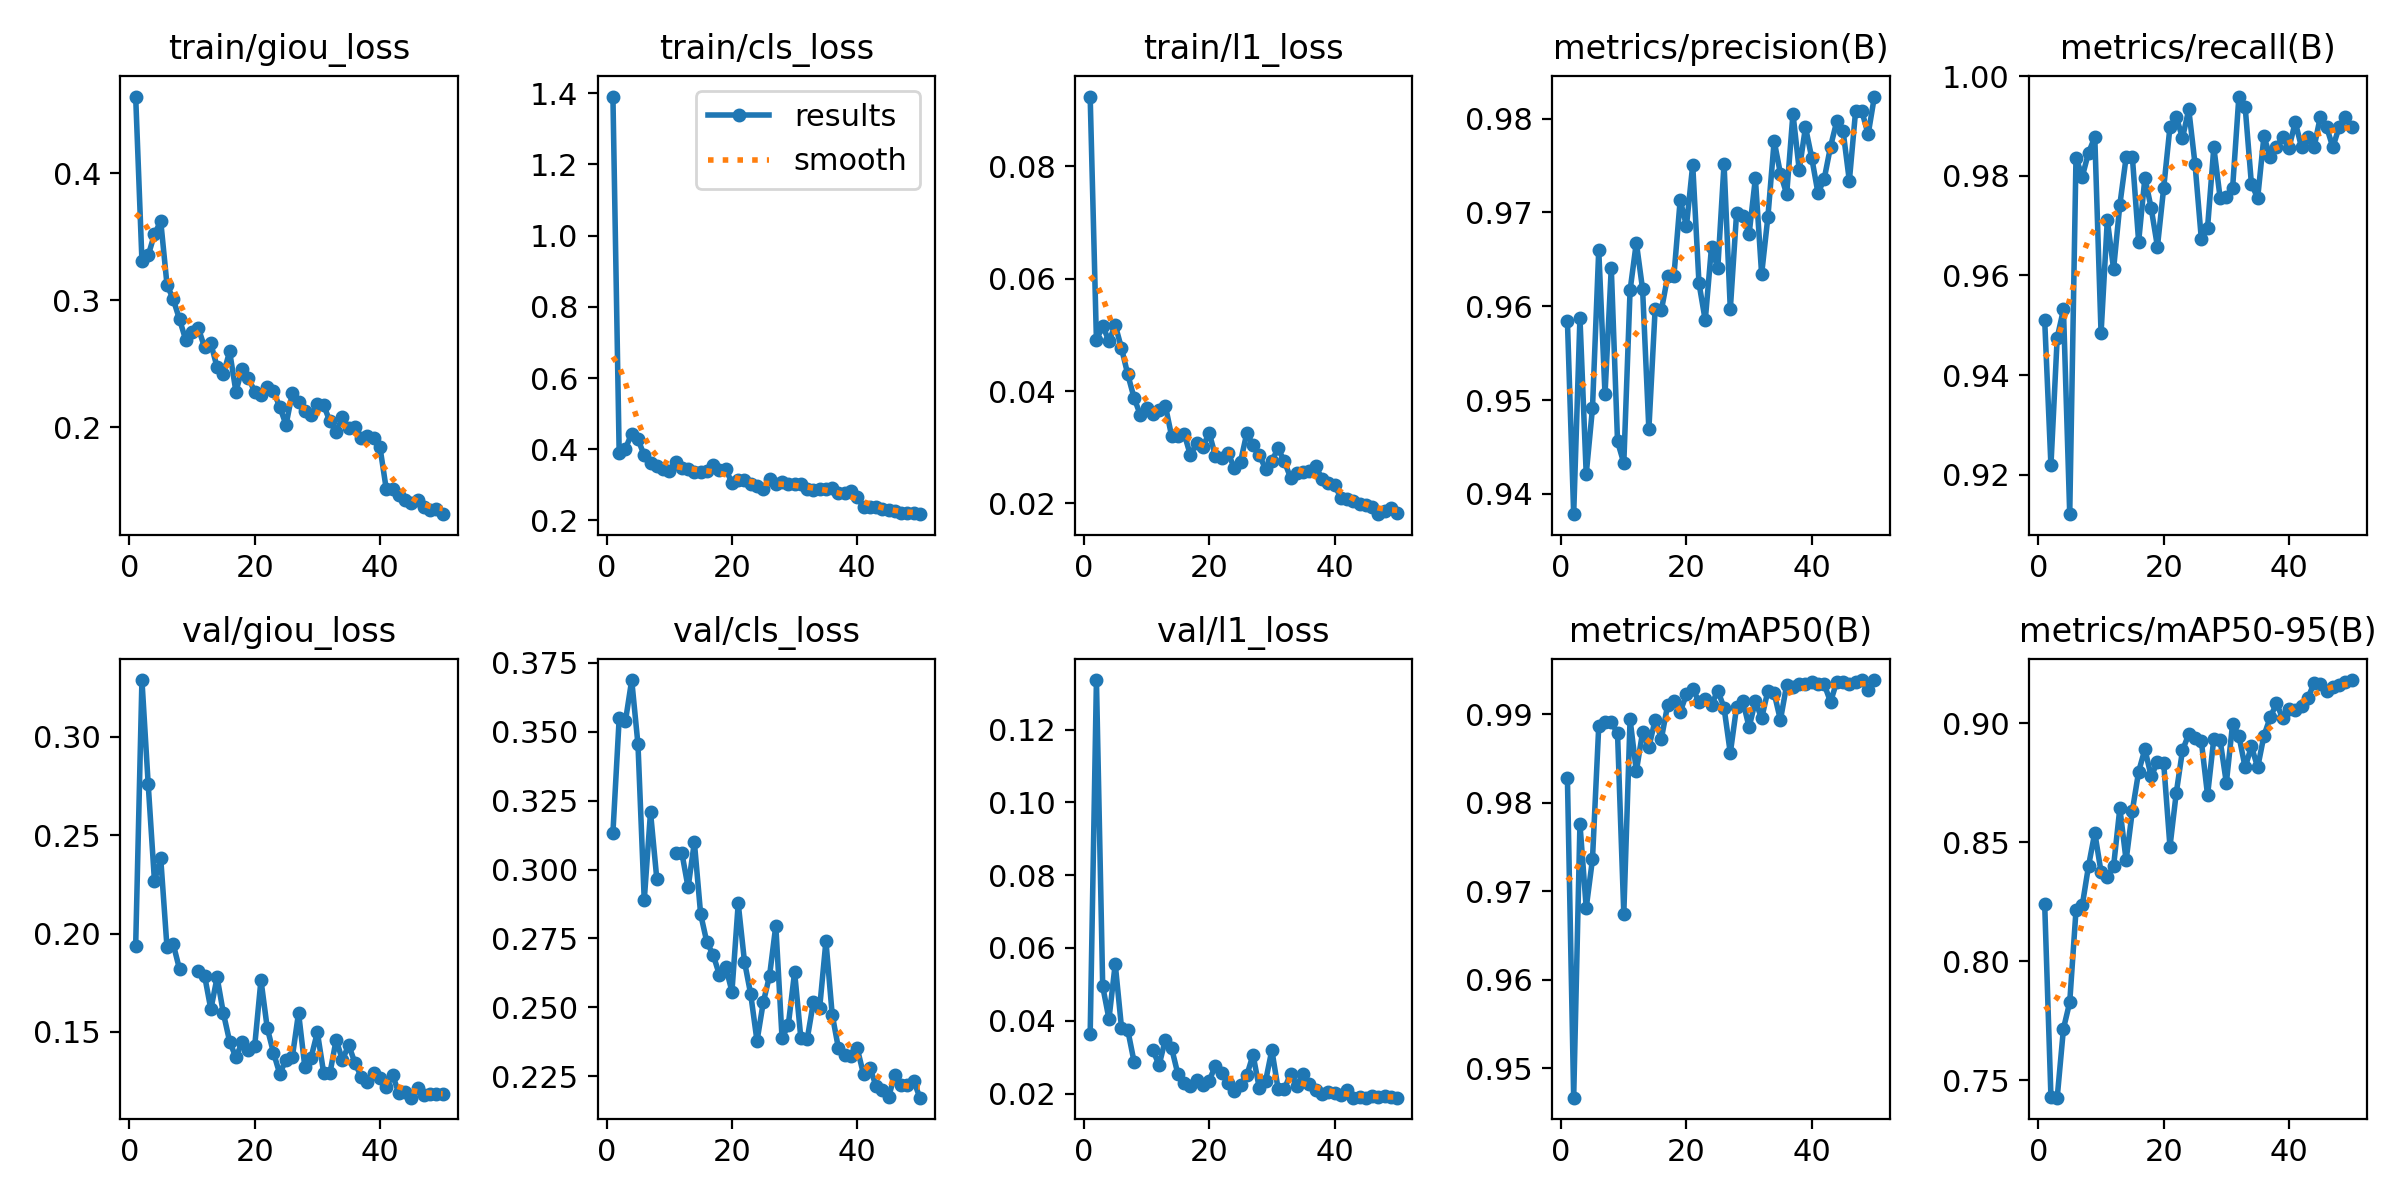

In [ ]:
display(Image("/content/drive/MyDrive/VC_P4/runs/rtdetr_matriculas/results.png"))

## 6. P4b · Comparativa OCR: EasyOCR vs SmolVLM (nueva sesión con GPU)

Ambos modelos se ejecutan en la misma máquina (GPU NVIDIA L4), con las mismas imágenes y el mismo post-procesado.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!nvidia-smi
!pip install -q easyocr
!unzip -q -n /content/drive/MyDrive/VC_P4/UC3M-LP.zip -d /content/UC3M-LP

Mounted at /content/drive
Sat Nov  7 12:54:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA L4                      Off |   00000000:00:03.0 Off |                    0 |
| N/A   49C    P8             14W /   72W |       0MiB /  23034MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------------

### 6.1 Selección de 150 matrículas del conjunto de test

Se recortan las matrículas de tipo A (turismos, una fila) de la partición de test de UC3M-LP y se eligen 150 al azar (`random.seed(0)`, para poder repetir el experimento).

Por privacidad, el conjunto de datos tapa con un recuadro gris dos de los siete caracteres de cada matrícula (marcados con `*` en la anotación). Como referencia se usan los **caracteres visibles**, p. ej. `24*0JV*` → `240JV`.

150 matrículas, 16 de ellas de noche


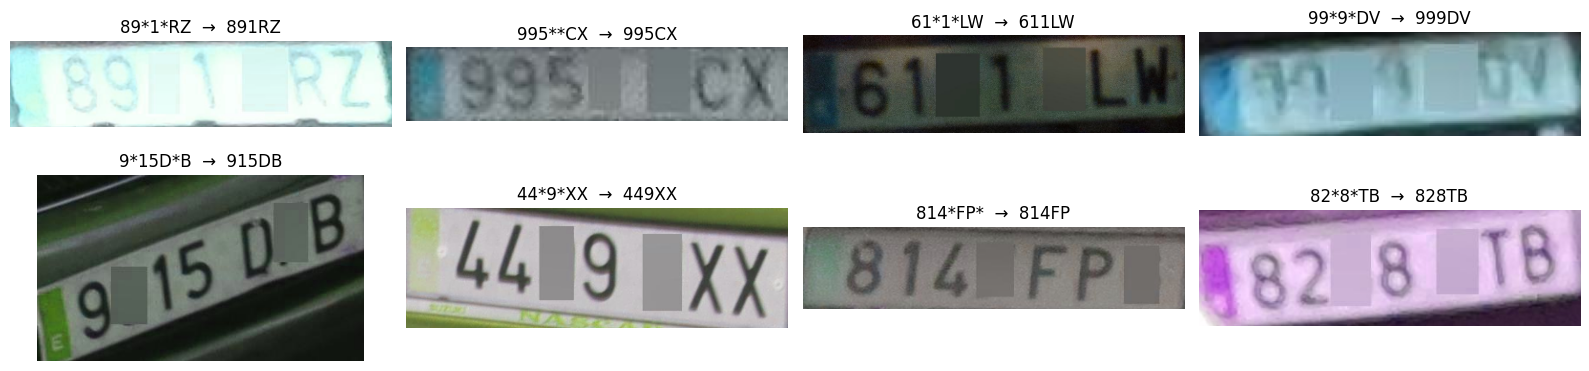

In [ ]:
import json, cv2, os, random
import pandas as pd
import matplotlib.pyplot as plt

RAIZ = '/content/UC3M-LP/UC3M-LP'
CARPETA = '/content/drive/MyDrive/VC_P4/ocr_test'          # guardar los recortes de forma permanente en Drive
os.makedirs(CARPETA, exist_ok=True)

nombres = open(f'{RAIZ}/test.txt').read().split()
muestras = []
for n in nombres:
    datos = json.load(open(f'{RAIZ}/test/{n}.json'))
    img = cv2.imread(f'{RAIZ}/test/{n}.jpg')
    for k, lp in enumerate(datos['lps']):
        tipo, mascara = lp['lp_id'].split('-', 1)            # p. ej. "AD", "24*0JV*"
        if tipo[0] != 'A':                                     # solo matrículas normales de turismo (tipo A)
            continue
        xs = [p[0] for p in lp['poly_coord']]
        ys = [p[1] for p in lp['poly_coord']]
        recorte = img[max(0, min(ys)):max(ys), max(0, min(xs)):max(xs)]
        if recorte.size == 0:
            continue
        if recorte.shape[1] > 400:                             # reducir los recortes muy grandes a 400 px de ancho
            recorte = cv2.resize(recorte, (400, int(400 * recorte.shape[0] / recorte.shape[1])))
        muestras.append({'archivo': f'{n}_{k}.jpg', 'recorte': recorte,
                         'texto_real': mascara.replace('*', ''), 'mascara': mascara,
                         'luz': 'día' if tipo[1] == 'D' else 'noche'})

random.seed(0)
random.shuffle(muestras)
muestras = muestras[:150]

for m in muestras:
    cv2.imwrite(os.path.join(CARPETA, m['archivo']), m['recorte'])
pd.DataFrame([{k: v for k, v in m.items() if k != 'recorte'} for m in muestras]).to_csv(
    os.path.join(CARPETA, 'referencia.csv'), index=False)

print(len(muestras), 'matrículas,', sum(m['luz'] == 'noche' for m in muestras), 'de ellas de noche')

fig, axs = plt.subplots(2, 4, figsize=(16, 4))
for ax, m in zip(axs.ravel(), muestras[:8]):
    ax.imshow(cv2.cvtColor(m['recorte'], cv2.COLOR_BGR2RGB))
    ax.set_title(f"{m['mascara']}  →  {m['texto_real']}")
    ax.axis('off')
plt.tight_layout(); plt.show()

### 6.2 Carga de los modelos

Basado en los ejemplos de EasyOCR y SmolVLM del cuaderno `VC_P4b.ipynb` de la asignatura.

In [ ]:
import time, re
import numpy as np
import torch
import easyocr
from PIL import Image
from transformers import AutoProcessor, AutoModelForImageTextToText

# --- EasyOCR (PLANTILLA del profesor, VC_P4b.ipynb) ---
reader = easyocr.Reader(['es'], gpu=True)                  # MODIFICADO: gpu=True

# --- SmolVLM (PLANTILLA del profesor, VC_P4b.ipynb) ---
Device = "cuda"                                             # MODIFICADO: GPU en lugar de "cpu"
processor = AutoProcessor.from_pretrained("HuggingFaceTB/SmolVLM-Instruct")
model_vlm = AutoModelForImageTextToText.from_pretrained("HuggingFaceTB/SmolVLM-Instruct",
                                                        dtype=torch.bfloat16,
                                                        _attn_implementation="eager").to(Device)   # MODIFICADO: "eager" en lugar de flash_attention_2 (no instalado en Colab)
print("Modelos cargados")

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

Modelos cargados


### 6.3 Inferencia con ambos modelos

El tiempo se mide por imagen, después de una llamada de calentamiento y sin contar la carga del modelo.

In [ ]:
# --- NUEVO: mismo post-procesado para AMBOS modelos (mismas condiciones) ---
def limpiar(texto):
    t = re.sub(r'[^A-Z0-9]', '', texto.upper())           # solo mayúsculas y dígitos
    if len(t) > 1 and t[0] == 'E' and t[1].isdigit():       # quitar la "E" de la franja azul de la UE
        t = t[1:]
    return t

# --- EasyOCR (PLANTILLA del profesor: reader.readtext) ---
def ocr_easyocr(recorte):
    res = reader.readtext(recorte, allowlist='0123456789ABCDEFGHIJKLMNOPQRSTUVWXYZ')   # MODIFICADO: allowlist con dígitos y mayúsculas
    res = sorted(res, key=lambda r: r[0][0][0])            # NUEVO: fragmentos de texto de izquierda a derecha
    return ''.join(r[1] for r in res)

# --- SmolVLM (PLANTILLA del profesor: mensaje, apply_chat_template, generate) ---
messages = [{"role": "user", "content": [
    {"type": "image"},
    {"type": "text", "text": "Can you give me the text in the license plate of the image? "
                             "Answer only with the characters."}]}]           # MODIFICADO: pedir solo los caracteres
prompt = processor.apply_chat_template(messages, add_generation_prompt=True)

def ocr_smolvlm(recorte):
    imagen = Image.fromarray(cv2.cvtColor(recorte, cv2.COLOR_BGR2RGB))       # NUEVO: imagen de OpenCV -> PIL
    inputs = processor(text=prompt, images=[imagen], return_tensors="pt").to(Device)
    generated_ids = model_vlm.generate(**inputs, max_new_tokens=16)
    nuevos = generated_ids[:, inputs['input_ids'].shape[1]:]                 # NUEVO: solo la respuesta, sin la pregunta
    return processor.batch_decode(nuevos, skip_special_tokens=True)[0]

# --- NUEVO: calentamiento (la primera llamada siempre es más lenta, no se mide) ---
ocr_easyocr(muestras[0]['recorte'])
ocr_smolvlm(muestras[0]['recorte'])

# --- NUEVO: medición ---
resultados = []
for m in muestras:
    for nombre, funcion in [('EasyOCR', ocr_easyocr), ('SmolVLM', ocr_smolvlm)]:
        t0 = time.perf_counter()
        bruto = funcion(m['recorte'])
        ms = (time.perf_counter() - t0) * 1000
        resultados.append({'modelo': nombre, 'archivo': m['archivo'], 'luz': m['luz'],
                           'texto_real': m['texto_real'], 'salida_bruta': bruto,
                           'prediccion': limpiar(bruto), 'ms': ms})
df = pd.DataFrame(resultados)
df.head(10)

,modelo,archivo,luz,texto_real,salida_bruta,prediccion,ms
0,EasyOCR,00588_0.jpg,día,891RZ,8811PZ,8811PZ,32.469931
1,SmolVLM,00588_0.jpg,día,891RZ,891rz.,891RZ,544.824070
2,EasyOCR,00879_0.jpg,día,995CX,995,995,43.839074
3,SmolVLM,00879_0.jpg,día,995CX,995.,995,475.580609
4,EasyOCR,00407_0.jpg,noche,611LW,6121LH,6121LH,33.302428
5,SmolVLM,00407_0.jpg,noche,611LW,611 LW.,611LW,819.569461
6,EasyOCR,00591_2.jpg,día,999DV,,,12.395375
7,SmolVLM,00591_2.jpg,día,999DV,3336v.,3336V,816.696867
8,EasyOCR,01597_1.jpg,día,915DB,915DB,915DB,43.468080
9,SmolVLM,01597_1.jpg,día,915DB,915 D.B.,915DB,1162.775614


### 6.4 Métricas y gráficas

- **Acierto exacto:** la matrícula leída coincide completamente con la referencia.
- **Acierto por carácter:** 1 − CER, donde CER = distancia de Levenshtein / longitud de la referencia.

         acierto_exacto    cer  ms_medio  acierto_caracteres
modelo                                                      
EasyOCR            0.18  0.350    24.742               0.650
SmolVLM            0.78  0.087   739.197               0.913

modelo  EasyOCR  SmolVLM
luz                     
día       0.179    0.799
noche     0.188    0.625


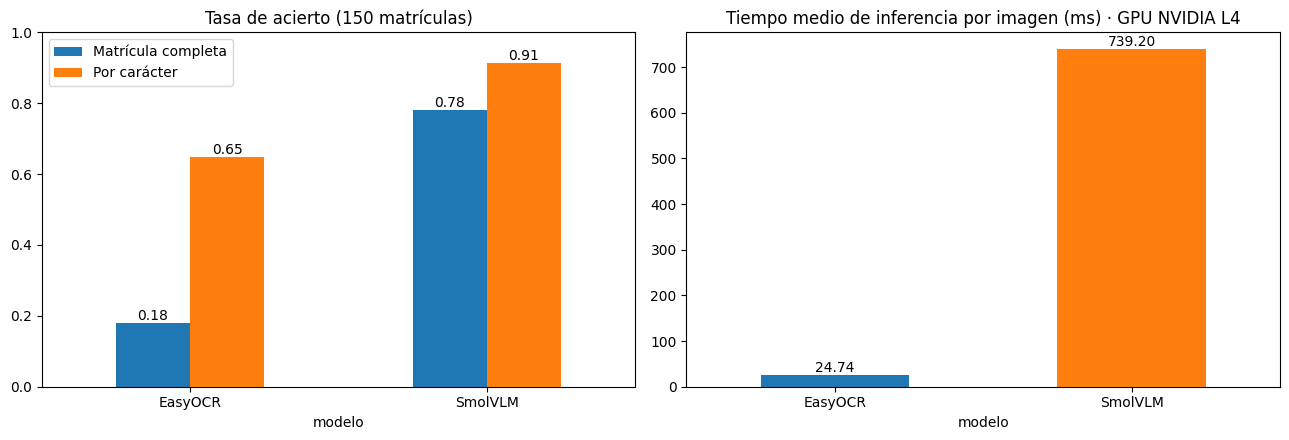

In [ ]:
# --- NUEVO: tasa de error por carácter (distancia de Levenshtein) ---
def levenshtein(a, b):
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i]
        for j, cb in enumerate(b, 1):
            cur.append(min(prev[j] + 1, cur[j-1] + 1, prev[j-1] + (ca != cb)))
        prev = cur
    return prev[-1]

df['acierto'] = df['prediccion'] == df['texto_real']
df['cer'] = [min(1, levenshtein(p, r) / len(r)) for p, r in zip(df['prediccion'], df['texto_real'])]

resumen = df.groupby('modelo').agg(acierto_exacto=('acierto', 'mean'),
                                   cer=('cer', 'mean'),
                                   ms_medio=('ms', 'mean'))
resumen['acierto_caracteres'] = 1 - resumen['cer']
print(resumen.round(3))
print()
print(df.pivot_table(index='luz', columns='modelo', values='acierto', aggfunc='mean').round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 4.5))
resumen[['acierto_exacto', 'acierto_caracteres']].plot.bar(ax=axs[0], rot=0)
axs[0].set_ylim(0, 1); axs[0].set_title('Tasa de acierto (150 matrículas)')
axs[0].legend(['Matrícula completa', 'Por carácter'])
resumen['ms_medio'].plot.bar(ax=axs[1], rot=0, color=['tab:blue', 'tab:orange'])
axs[1].set_title('Tiempo medio de inferencia por imagen (ms) · GPU NVIDIA L4')
for ax in axs:
    for p in ax.patches:
        ax.annotate(f'{p.get_height():.2f}', (p.get_x() + p.get_width()/2, p.get_height()), ha='center', va='bottom')
plt.tight_layout()
plt.savefig('/content/drive/MyDrive/VC_P4/ocr_comparativa.png', dpi=150)
plt.show()

df.to_csv('/content/drive/MyDrive/VC_P4/ocr_resultados.csv', index=False)

### 6.5 Especificaciones de la máquina

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!lscpu | grep "Model name"
!free -h | grep Mem

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
Mem:            52Gi       8.5Gi        10Gi        17Mi        35Gi        44Gi
